# 5.1 Baseline maths for material properties

Before any machine learning, how far do **simple sums** get us? Whatever the **Material strength** model in 5.2 does has to beat the numbers here, or it is not worth its complexity.

Four steps:
1. **Guess the average**: every block gets the average strength. This is the floor.
2. **Foam rule**: strength from density with one power law, as engineers do for foams.
3. **Treatments**: how much pressing, coating, compaction and baking change strength and density, measured as a multiplier from matched pairs.
4. **Compare with products**: where our blocks and the foam rule sit against the benchmarks from 0.2.

**Strength** here is compressive stress at 10% strain (MPa). **Fold error** = how far off a prediction typically is, as a factor: 1.0 is perfect, 2.0 means typically half or double the real value. Every rule is scored by **leaving one lab out**: the rule is worked out on the other labs and tested on the hidden one, so it is never tested on blocks it has already seen.

A row can stand for one block or for a group mean; rows are weighted by how many blocks they stand for (`n_specimens`).

In [1]:
import json
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mycodemo.config import PROJ_ROOT
from mycodemo.property_data import build_property_table, load_tables

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
NAMES = {"d004": "Bhaskar 2026", "d005": "Elsacker 2019", "d006": "Hysek 2025", "d007": "Irbe 2026",
         "d016": "Vašatko 2022", "d017": "Jiménez-Obando 2025", "d023": "Houette 2022"}
LAB_STYLE = {"d004": ("#2a78d6", "o"), "d005": ("#1baf7a", "s"),  # same colours as 0.2
             "d007": ("#6250d6", "^"), "d016": ("#e87ba4", "v")}

table = build_property_table(load_tables())  # read only, nothing is saved

# "Plain" blocks: oven dried only, not pressed, not coated, not compacted
plain = table[(table.post_treatment == "oven_dry") & (table.pre_compressed == 0)]
both = plain.dropna(subset=["stress_mpa", "density_kg_m3"]).copy()
both["log_s"] = np.log10(both.stress_mpa)
both["log_d"] = np.log10(both.density_kg_m3)
print(f"{len(both)} plain rows with both strength and density "
      f"({int(both.n_specimens.sum())} blocks) from {both.dataset_id.nunique()} labs")
both.groupby("dataset_id").agg(rows=("sample_id", "size"), blocks=("n_specimens", "sum"),
                               median_density=("density_kg_m3", "median"),
                               median_strength=("stress_mpa", "median")).round(3)

2026-10-12 16:01:50.945 | INFO     | mycodemo.config:<module>:11 - PROJ_ROOT path is: /home/sylas/Desktop/mycodemo


87 plain rows with both strength and density (119 blocks) from 4 labs


,rows,blocks,median_density,median_strength
dataset_id,,,,
d004,58,58,210.758,0.152
d005,19,19,92.300,0.019
d007,8,40,149.000,0.091
d016,2,2,253.950,0.108


In [2]:
def plain_ticks(ax):
    # Log axes with ordinary numbers instead of 10^x
    for axis, values in [(ax.xaxis, [10, 20, 50, 100, 200, 500, 1000, 2000]),
                         (ax.yaxis, [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50])]:
        lo, hi = (ax.get_xlim() if axis is ax.xaxis else ax.get_ylim())
        shown = [v for v in values if lo <= v <= hi]
        axis.set_ticks(shown, [f"{v:g}" for v in shown])
        axis.set_minor_locator(plt.NullLocator())


def fold_error(true, pred, weights):
    # Typical factor between prediction and truth (weighted, on the log scale)
    err = np.abs(np.log10(pred) - np.log10(true))
    return float(10 ** np.average(err, weights=weights))


def leave_one_lab_out(df, fit, predict):
    # fit(train) -> rule; predict(rule, test) -> predicted strength
    rows = []
    for lab in sorted(df.dataset_id.unique()):
        train, test = df[df.dataset_id != lab], df[df.dataset_id == lab]
        rule = fit(train)
        rows.append(test.assign(pred=predict(rule, test)))
    return pd.concat(rows)


def score(pred_by_rule):
    # One row per held-out lab, one column per rule, plus an 'all labs' row
    out = {}
    for name, p in pred_by_rule.items():
        col = {lab: fold_error(g.stress_mpa, g.pred, g.n_specimens) for lab, g in p.groupby("dataset_id")}
        col["all labs"] = fold_error(p.stress_mpa, p.pred, p.n_specimens)
        out[name] = col
    return pd.DataFrame(out).round(2)

## 1. Guess the average

The strength of every block in the hidden lab is guessed as the average strength of the other labs. The average is taken on the log scale (a geometric mean), because strength spans 0.003 to 0.3 MPa and an ordinary average would be pulled up by the few strong blocks.

In [3]:
def fit_average(train):
    return np.average(train.log_s, weights=train.n_specimens)


def predict_average(rule, test):
    return np.full(len(test), 10 ** rule)


pred = {"average": leave_one_lab_out(both, fit_average, predict_average)}
print(f"Average of all plain blocks: {10 ** fit_average(both):.3f} MPa")
score(pred)

Average of all plain blocks: 0.085 MPa


,average
d004,2.88
d005,5.77
d007,1.93
d016,1.26
all labs,2.78


## 2. Foam rule (Gibson and Ashby)

Mycelium blocks behave like a foam: a network of thin walls (hyphae and fibre) with lots of air. For foams, Gibson and Ashby showed that strength rises with density to a power:

**strength = C × density<sup>n</sup>**

- For open-cell foams the textbook power is **n = 1.5**: double the density, and strength rises about 2.8 times.
- C sets the overall level and depends on the material the walls are made of.

On a log–log chart this is a straight line with slope n. We try two versions:
- **textbook**: n fixed at 1.5, only C worked out from the training labs;
- **fitted**: both n and C worked out from the training labs.

In [4]:
def fit_textbook(train):
    c = np.average(train.log_s - 1.5 * train.log_d, weights=train.n_specimens)
    return (1.5, c)


def fit_power(train):
    n, c = np.polyfit(train.log_d, train.log_s, 1, w=np.sqrt(train.n_specimens))
    return (n, c)


def predict_power(rule, test):
    n, c = rule
    return 10 ** (c + n * test.log_d)


pred["foam rule, n = 1.5"] = leave_one_lab_out(both, fit_textbook, predict_power)
pred["foam rule, fitted n"] = leave_one_lab_out(both, fit_power, predict_power)

N_ALL, C_ALL = fit_power(both)
C_15 = fit_textbook(both)[1]
print(f"Fitted on all plain blocks: strength = {10 ** C_ALL:.2e} × density^{N_ALL:.2f}")
print(f"Textbook n = 1.5:           strength = {10 ** C_15:.2e} × density^1.5")
score(pred)

Fitted on all plain blocks: strength = 2.38e-06 × density^2.05
Textbook n = 1.5:           strength = 3.96e-05 × density^1.5


,average,"foam rule, n = 1.5","foam rule, fitted n"
d004,2.88,1.69,1.54
d005,5.77,2.24,1.97
d007,1.93,1.32,1.19
d016,1.26,1.51,1.93
all labs,2.78,1.63,1.47


### Inside each lab

The foam rule says denser blocks are stronger. Does that hold inside one lab, where the recipe and test method are the same? The fitted power n per lab answers this. (d016 has only 2 plain rows with both values, so its n means little.)

In [5]:
per_lab = pd.DataFrame({lab: dict(zip(["n", "log C"], fit_power(g))) | {"rows": len(g)}
                        for lab, g in both.groupby("dataset_id")}).T
per_lab["n"] = per_lab["n"].astype(float).round(2)
per_lab[["rows", "n"]]

,rows,n
d004,58.0,0.07
d005,19.0,0.69
d007,8.0,2.31
d016,2.0,9.76


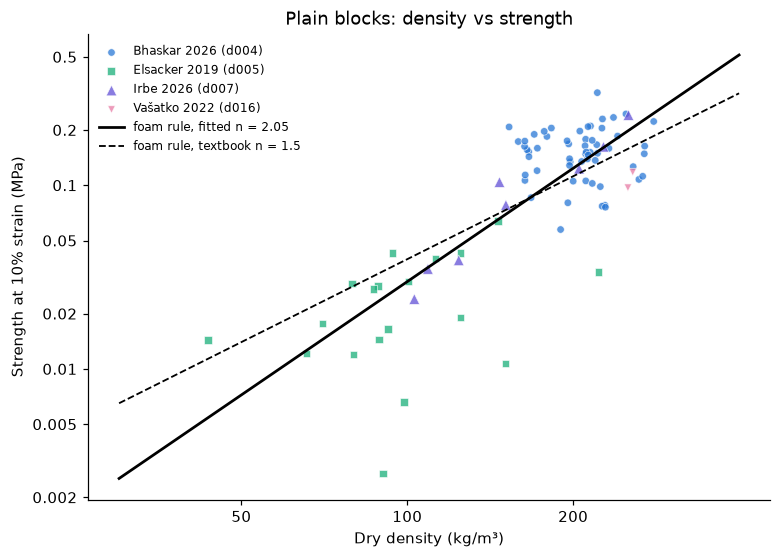

In [6]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for lab, (colour, marker) in LAB_STYLE.items():
    g = both[both.dataset_id == lab]
    ax.scatter(g.density_kg_m3, g.stress_mpa, c=colour, marker=marker, s=18 + 6 * g.n_specimens,
               alpha=0.75, edgecolors="white", linewidths=0.5, label=f"{NAMES[lab]} ({lab})")
x = np.geomspace(30, 400, 50)
ax.plot(x, 10 ** (C_ALL + N_ALL * np.log10(x)), color="black", lw=1.8,
        label=f"foam rule, fitted n = {N_ALL:.2f}")
ax.plot(x, 10 ** (C_15 + 1.5 * np.log10(x)), color="black", lw=1.2, ls="--",
        label="foam rule, textbook n = 1.5")
ax.set(xscale="log", yscale="log", xlabel="Dry density (kg/m³)",
       ylabel="Strength at 10% strain (MPa)", title="Plain blocks: density vs strength")
plain_ticks(ax)
ax.legend(fontsize=8, frameon=False)
plt.show()

**How to read it:** if the foam rule were the whole story, every lab's points would lie along the black line. Bigger markers stand for more blocks (group means).

## 3. Treatments: how much does each one change the outcome?

Treatments are things done to the block during or after growth. Our data hold four:

| Treatment | When | Lab | What was done |
|---|---|---|---|
| Pressed while growing | during growth | d005 Elsacker 2019 | block compressed from 100 to 80 mm while the fungus grew |
| Chitosan coating, 2 or 4 layers | after drying | d007 Irbe 2026 | chitosan (from crab shells) brushed on in layers |
| Compacted after growth | after growth, before drying | d023 Houette 2022 | wet block pressed to half its thickness, then dried |
| Oven bake instead of oven dry | drying | d023 Houette 2022 | dried at a higher, baking temperature |

The fair way to measure a treatment is a **matched pair**: the same lab, the same substrate and the same recipe, once without and once with the treatment. The **multiplier** is treated ÷ untreated: 2.0 means doubled, 0.5 means halved, 1.0 means no change. With several pairs we take their geometric mean.

d023 measured density only, so compaction and baking have no strength multiplier.

In [7]:
def ratio_rows(treatment, untreated, treated, key):
    # Geometric mean per matched group, then treated / untreated for strength and density
    rows = []
    for col, prop in [("stress_mpa", "strength"), ("density_kg_m3", "density")]:
        a = untreated.dropna(subset=[col]).groupby(key)[col].apply(lambda v: 10 ** np.log10(v).mean())
        b = treated.dropna(subset=[col]).groupby(key)[col].apply(lambda v: 10 ** np.log10(v).mean())
        for k in a.index.intersection(b.index):
            rows.append(dict(treatment=treatment, property=prop, pair=k,
                             untreated=a[k], treated=b[k], multiplier=b[k] / a[k]))
    return rows


pairs = []

# Pressed while growing (d005): untreated = same fibre, same particle size, not pressed
d5 = table[(table.dataset_id == "d005") & table.pre_compressed.notna()].copy()
d5["key"] = d5.plant_name + ", size class " + d5.particle_size_class.astype(int).astype(str)
pairs += ratio_rows("Pressed while growing", d5[d5.pre_compressed == 0], d5[d5.pre_compressed == 1], "key")

# Chitosan coating (d007): sample ids end in -C0 (none), -C2 or -C4 (layers)
d7 = table[table.dataset_id == "d007"].copy()
d7["key"] = d7.sample_id.str.replace(r"-C\d$", "", regex=True)
d7["layers"] = d7.sample_id.str[-1].astype(int)
for n in (2, 4):
    pairs += ratio_rows(f"Chitosan coating, {n} layers", d7[d7.layers == 0], d7[d7.layers == n], "key")

# d023: ids end in <group>-<size><NC or C><D or B>: NC/C = not compacted / compacted, D/B = dry / bake
d23 = table[table.dataset_id == "d023"].copy()
parts = d23.sample_id.str.extract(r"-(?P<group>PO|CC)-(?P<size>[SL])(?P<compact>N?C)(?P<dry>[DB])$")
d23 = d23.join(parts)
d23["key_c"] = d23.group + "-" + d23["size"] + ", " + d23.dry.map({"D": "dried", "B": "baked"})
d23["key_b"] = d23.group + "-" + d23["size"] + ", " + d23.compact.map({"NC": "not compacted", "C": "compacted"})
pairs += ratio_rows("Compacted after growth", d23[d23.compact == "NC"], d23[d23.compact == "C"], "key_c")
pairs += ratio_rows("Oven bake instead of dry", d23[d23.dry == "D"], d23[d23.dry == "B"], "key_b")

pairs = pd.DataFrame(pairs)
pairs.round(3)

,treatment,property,pair,untreated,treated,multiplier
0,Pressed while growing,strength,"flax waste, size class 3",0.020,0.062,3.152
1,Pressed while growing,strength,"flax, size class 3",0.018,0.052,2.876
2,Pressed while growing,strength,"hemp, size class 3",0.013,0.091,7.166
3,Pressed while growing,density,"flax waste, size class 3",95.827,159.295,1.662
4,Pressed while growing,density,"flax, size class 3",58.512,68.666,1.174
5,Pressed while growing,density,"hemp, size class 3",88.588,72.300,0.816
6,"Chitosan coating, 2 layers",strength,d007-G-BSD1,0.241,0.113,0.469
7,"Chitosan coating, 2 layers",strength,d007-G-BSD2,0.104,0.082,0.788
8,"Chitosan coating, 2 layers",strength,d007-G-BSD3,0.123,0.110,0.894
9,"Chitosan coating, 2 layers",strength,d007-G-BSD4,0.162,0.080,0.494


In [8]:
TREATMENTS = list(dict.fromkeys(pairs.treatment))
# One row per treatment: multiplier (geometric mean of the pairs), number of pairs and range
def describe(m):
    return f"×{10 ** np.log10(m).mean():.2f} ({len(m)} pairs, {m.min():.2f}–{m.max():.2f})"


summary = (pairs.groupby(["treatment", "property"], sort=False).multiplier.apply(describe)
           .unstack("property").reindex(TREATMENTS)[["strength", "density"]].fillna("not measured"))
summary

property,strength,density
treatment,,
Pressed while growing,"×4.02 (3 pairs, 2.88–7.17)","×1.17 (3 pairs, 0.82–1.66)"
"Chitosan coating, 2 layers","×0.67 (8 pairs, 0.47–0.91)","×0.85 (8 pairs, 0.69–0.97)"
"Chitosan coating, 4 layers","×0.73 (7 pairs, 0.53–1.00)","×0.89 (7 pairs, 0.84–1.00)"
Compacted after growth,not measured,"×1.47 (6 pairs, 1.20–1.60)"
Oven bake instead of dry,not measured,"×1.03 (6 pairs, 0.87–1.15)"


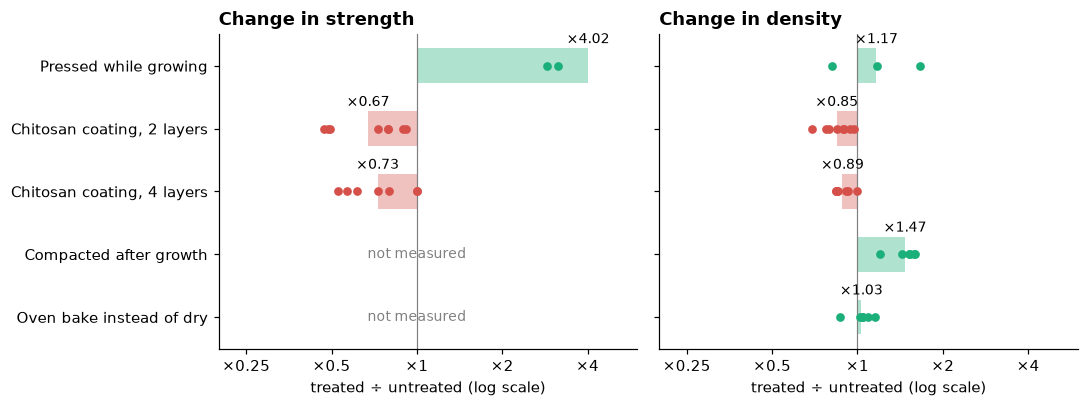

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, prop in zip(axes, ["strength", "density"]):
    for i, t in enumerate(TREATMENTS):
        m = pairs[(pairs.treatment == t) & (pairs.property == prop)].multiplier
        if m.empty:
            ax.text(0, i, "not measured", ha="center", va="center", color="grey", fontsize=9)
            continue
        gm = 10 ** np.log10(m).mean()
        colour = "#1baf7a" if gm >= 1 else "#d6504a"
        ax.barh(i, np.log10(gm), left=0, height=0.55, color=colour, alpha=0.35)
        ax.scatter(np.log10(m), np.full(len(m), i), color=colour, s=22, zorder=3)
        ax.text(np.log10(gm), i - 0.36, f"×{gm:.2f}", ha="center", fontsize=9)
    ticks = [0.25, 0.5, 1, 2, 4]
    ax.set_xticks(np.log10(ticks), [f"×{t:g}" for t in ticks])
    ax.set_xlim(np.log10(0.2), np.log10(6))
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(f"Change in {prop}", loc="left", fontweight="bold")
    ax.set_xlabel("treated ÷ untreated (log scale)")
axes[0].set_yticks(range(len(TREATMENTS)), TREATMENTS)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

**How to read it:** each dot is one matched pair, the bar is their geometric mean. Green = the treatment raised the value, red = lowered it. "not measured" means the lab did not test that property.

### Does adding the multiplier help the foam rule?

The foam rule only sees density. A treatment that changes strength *without* changing density (or the other way round) will fool it. Here the foam rule (fitted on all plain blocks) predicts each treated block from its measured density, once on its own and once multiplied by the treatment's **strength-only** effect.

The strength-only effect is the strength multiplier divided by what the density change alone would give through the foam rule (density multiplier<sup>n</sup>). To keep the test fair, the multiplier for a pair is worked out from the **other** pairs only (leave one pair out). The plain blocks of these labs were used to fit the foam rule, so this check is a little optimistic.

In [10]:
def treated_rows(treatment):
    # Treated blocks with strength and density, labelled with their matched-pair key
    if treatment == "Pressed while growing":
        rows = d5[d5.pre_compressed == 1]
    else:
        n = int(re.search(r"(\d) layers", treatment).group(1))
        rows = d7[d7.layers == n]
    return rows.dropna(subset=["stress_mpa", "density_kg_m3"])


checks = []
for t in ["Pressed while growing", "Chitosan coating, 2 layers", "Chitosan coating, 4 layers"]:
    rows = treated_rows(t)
    p = pairs[pairs.treatment == t].pivot(index="pair", columns="property", values="multiplier")
    p = p.dropna()
    # strength change not explained by the density change
    p["own_effect"] = p.strength / p.density ** N_ALL
    foam = 10 ** (C_ALL + N_ALL * np.log10(rows.density_kg_m3))
    mult = rows.key.map(lambda k: 10 ** np.log10(p.own_effect.drop(index=k, errors="ignore")).mean())
    checks.append(dict(treatment=t, rows=len(rows),
                       strength_only_multiplier=round(10 ** np.log10(p.own_effect).mean(), 2),
                       foam_rule=fold_error(rows.stress_mpa, foam, rows.n_specimens),
                       foam_rule_x_multiplier=fold_error(rows.stress_mpa, foam * mult, rows.n_specimens)))
pd.DataFrame(checks).round(2)

,treatment,rows,strength_only_multiplier,foam_rule,foam_rule_x_multiplier
0,Pressed while growing,6,2.93,3.59,2.39
1,"Chitosan coating, 2 layers",8,0.95,1.25,1.26
2,"Chitosan coating, 4 layers",7,0.93,1.30,1.31


## 4. Compare with products

The benchmark values are read straight from the table typed in `0.2.benchmarks.ipynb`, so there is only one copy of them. Only checked or patent-backed values with both a density and a strength are drawn, including the conventional materials (foams, wood, bricks) added to 0.2. Claims are hollow, measured values filled; a light box shows a range. Strain differs: the GIY kit is tested at 15%, Okom does not say, ours and the standards at 10%.

In [11]:
# Run only the cell of 0.2 that builds the benchmark table (as 0.3 does)
nb02 = json.loads((PROJ_ROOT / "notebooks" / "0.2.benchmarks.ipynb").read_text(encoding="utf-8"))
bench_cell = next("".join(c["source"]) for c in nb02["cells"]
                  if c["cell_type"] == "code" and "rows = [" in "".join(c["source"]))
ns = {"pd": pd}
exec(bench_cell, ns)
marks = ns["shown"].dropna(subset=["density_kg_m3_lo", "stress_MPa_lo"])

marks = marks.assign(foam_rule_MPa=10 ** (C_ALL + N_ALL * np.log10(marks.density_kg_m3_lo)))
marks[["benchmark", "category", "kind", "density_kg_m3_lo", "stress_MPa_lo", "foam_rule_MPa"]].round(3)

family    status   
eco       checked       6
          no_source     2
          patent        4
lab       checked       1
other     checked       2
          no_source     5
          patent        9
standard  checked      14


,benchmark,category,kind,density_kg_m3_lo,stress_MPa_lo,foam_rule_MPa
0,GIY kit material,kit,measured,122.0,0.124,0.045
3,Grown.bio packaging,packaging,measured,115.5,0.002,0.040
12,Mogu acoustic panels,acoustic panel,measured,120.0,0.011,0.043
13,Okom Wrks boards,board,claim,250.0,1.200,0.195
14,Okom Wrks example,board,measured,250.0,0.980,0.195
29,EPS foam (EPS 70–100),insulation,declared,15.0,0.070,0.001
30,XPS board,insulation,declared,32.0,0.300,0.003
31,PIR board,insulation,declared,32.0,0.150,0.003
32,Stone wool board,insulation,declared,144.0,0.030,0.063
33,Wood fibre board,insulation,declared,180.0,0.200,0.100


In [12]:
pressed = table[(table.dataset_id == "d005") & (table.pre_compressed == 1)].dropna(
    subset=["stress_mpa", "density_kg_m3"])
coated = table[table.coated].dropna(subset=["stress_mpa", "density_kg_m3"])
ours = pd.concat([both.assign(how="plain"), pressed.assign(how="pressed while growing"),
                  coated.assign(how="chitosan coated")])
HOW_MARKER = {"plain": "o", "pressed while growing": "s", "chitosan coated": "^"}
mycelium = marks[marks.family != "standard"]   # mycelium products and claims
standard = marks[marks.family == "standard"]   # conventional materials, for scale


def draw_mark(ax, r, colour, marker):
    # A point at the low value; a light box when the source gives a range
    x0, y0 = r.density_kg_m3_lo, r.stress_MPa_lo
    x1 = r.density_kg_m3_hi if pd.notna(r.density_kg_m3_hi) else x0
    y1 = r.stress_MPa_hi if pd.notna(r.stress_MPa_hi) else y0
    if x1 > x0 or y1 > y0:
        ax.add_patch(plt.Rectangle((x0, y0), max(x1 - x0, x0 * 0.02), max(y1 - y0, y0 * 0.02),
                                   facecolor=colour, alpha=0.12, edgecolor=colour, lw=0.8))
    filled = r.kind != "claim"
    ax.scatter(x0, y0, marker=marker, s=60, color=colour, facecolors=colour if filled else "none",
               linewidths=1.5, zorder=4)
    ax.annotate(r.benchmark.split(" (")[0], (x0, y0), xytext=(5, 3), textcoords="offset points", fontsize=7, color=colour)


def setup(ax, title):
    x = np.geomspace(10, 2000, 50)
    ax.plot(x, 10 ** (C_ALL + N_ALL * np.log10(x)), color="black", lw=1.2, ls="--",
            label=f"foam rule, n = {N_ALL:.2f}")
    ax.set(xscale="log", yscale="log", xlim=(10, 2000), ylim=(0.001, 60), xlabel="Dry density (kg/m³)",
           ylabel="Strength at 10% strain (MPa)", title=title)
    plain_ticks(ax)

### 4a. Coloured by substrate

Our blocks are coloured by the substrate group they grew on; the marker shape says how they were treated. The mycelium products' sources do not name their substrate, so they are drawn in grey. Conventional materials (foams, wood, bricks) contain no substrate and are drawn as small grey crosses, for scale.

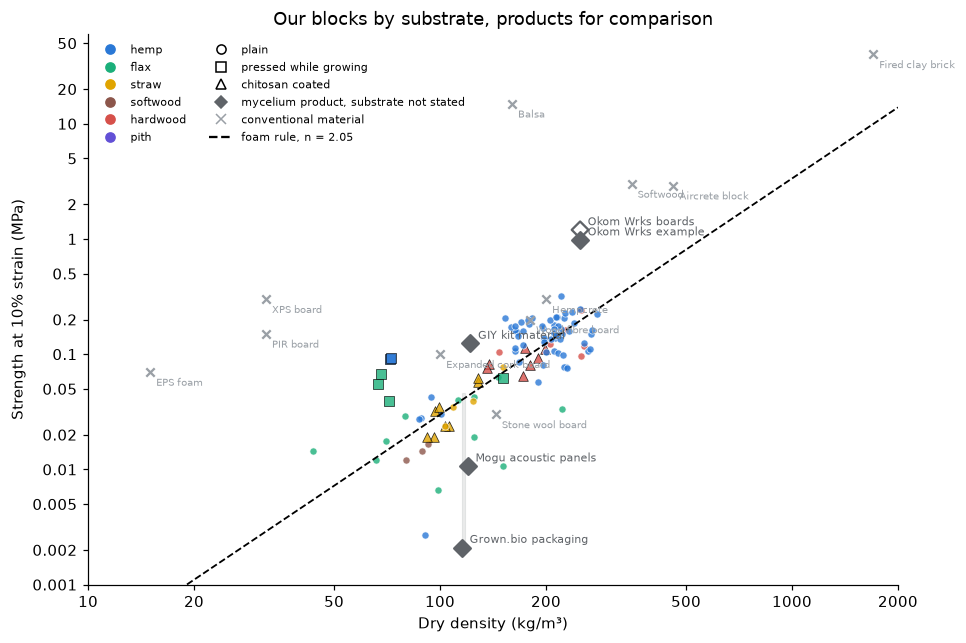

In [13]:
SUBSTRATE_COLOUR = {"hemp": "#2a78d6", "flax": "#1baf7a", "straw": "#e0a400", "softwood": "#8c564b",
                    "hardwood": "#d6504a", "pith": "#6250d6"}

fig, ax = plt.subplots(figsize=(9.5, 6.5))
setup(ax, "Our blocks by substrate, products for comparison")
for (group, how), g in ours.groupby(["substrate_group", "how"]):
    ax.scatter(g.density_kg_m3, g.stress_mpa, c=SUBSTRATE_COLOUR[group], marker=HOW_MARKER[how],
               s=22 if how == "plain" else 40, alpha=0.8, edgecolors="white" if how == "plain" else "black",
               linewidths=0.5)
for _, r in mycelium.iterrows():
    draw_mark(ax, r, "#5f6368", "D")
for _, r in standard.iterrows():
    ax.scatter(r.density_kg_m3_lo, r.stress_MPa_lo, marker="x", s=30, color="#9aa0a6")
    ax.annotate(r.benchmark.split(" (")[0], (r.density_kg_m3_lo, r.stress_MPa_lo), xytext=(4, -9),
                textcoords="offset points", fontsize=6.5, color="#9aa0a6")
handles = [plt.Line2D([], [], ls="", marker="o", color=c, label=s) for s, c in SUBSTRATE_COLOUR.items()]
handles += [plt.Line2D([], [], ls="", marker=m, color="black", mfc="none", label=h) for h, m in HOW_MARKER.items()]
handles += [plt.Line2D([], [], ls="", marker="D", color="#5f6368", label="mycelium product, substrate not stated"),
            plt.Line2D([], [], ls="", marker="x", color="#9aa0a6", label="conventional material"),
            plt.Line2D([], [], ls="--", color="black", label=f"foam rule, n = {N_ALL:.2f}")]
ax.legend(handles=handles, fontsize=7.5, frameon=False, loc="upper left", ncol=2)
plt.show()

### 4b. Coloured by what the product is meant to be

Colours come from the `category` column of the 0.2 table. Diamonds are mycelium products (filled = measured, hollow = claim), squares are conventional materials of the same category. Our lab blocks were made for research, not for one product, so they stay grey.

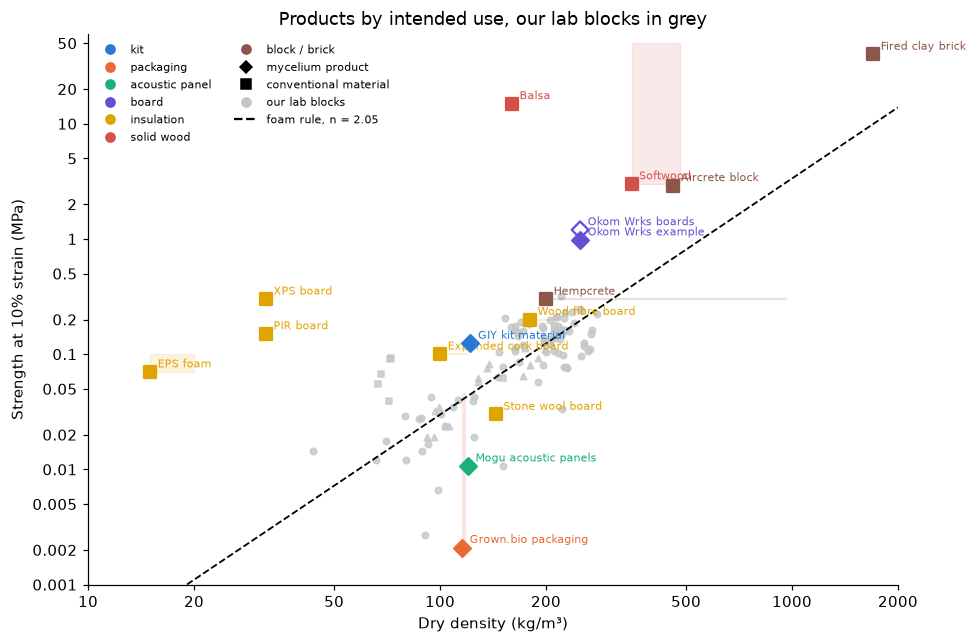

In [14]:
cats = [c for c in dict.fromkeys(marks.category)]
palette = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#e0a400", "#d6504a", "#8c564b", "#e87ba4", "#17becf"]
CATEGORY_COLOUR = dict(zip(cats, palette))

fig, ax = plt.subplots(figsize=(9.5, 6.5))
setup(ax, "Products by intended use, our lab blocks in grey")
for how, g in ours.groupby("how"):
    ax.scatter(g.density_kg_m3, g.stress_mpa, c="#c4c7c5", marker=HOW_MARKER[how], s=18, alpha=0.8)
for _, r in marks.iterrows():
    draw_mark(ax, r, CATEGORY_COLOUR[r.category], "s" if r.family == "standard" else "D")
handles = [plt.Line2D([], [], ls="", marker="o", color=c, label=k) for k, c in CATEGORY_COLOUR.items()]
handles += [plt.Line2D([], [], ls="", marker="D", color="black", label="mycelium product"),
            plt.Line2D([], [], ls="", marker="s", color="black", label="conventional material"),
            plt.Line2D([], [], ls="", marker="o", color="#c4c7c5", label="our lab blocks"),
            plt.Line2D([], [], ls="--", color="black", label=f"foam rule, n = {N_ALL:.2f}")]
ax.legend(handles=handles, fontsize=7.5, frameon=False, loc="upper left", ncol=2)
plt.show()

## 5. The bar for 5.2

Fill this in after Run All, from the tables above:

- **Leave one lab out, plain blocks:** average guess = ×…, foam rule (n = 1.5) = ×…, foam rule (fitted n) = ×…. A **Material strength** model is only useful if it beats the best of these.
- **Inside a lab:** fitted n per lab = … (compare with 1.5).
- **Treatments:** pressing while growing ×… strength, density ×…; chitosan 2 / 4 layers ×… / ×…; compaction after growth ×… density; baking ×… density.

**Limits of this notebook**
- Each treatment comes from one lab only (3 to 8 pairs), so its multiplier may not carry over to other fungi or substrates.
- The foam rule needs the measured density, which is only known after drying. Predicting density from the recipe is the job of 5.2.
- d023 (compaction, baking) measured no strength.